# The 32 screening factors against the seven orthogonal factors

Notebook `04_factor_screening` of the companion repository tests 32 factors one by one. Each one here is the long-short portfolio of the top 30% minus the bottom 30% of the investable universe on its signal, a cross-sectional z-score with the values beyond 2 standard deviations dropped, equally weighted and rebalanced monthly.

Used as test assets, like the industries of Table 7 of the paper, they answer two questions. How much of each factor is just a combination of the seven local factors, and which of them it resembles? And does any of them earn a return the seven factors do not explain?

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_screening, to_monthly, BRAZIL_FACTORS,
                               MONTHLY_SAMPLE)
from orthofactors.decomposition import decompose, variance_levels
from orthofactors.plotting import set_style, SEQUENTIAL

set_style()
Path('results').mkdir(exist_ok = True)

groups = {'Value': ['Book to Price', 'EV to Ebitda', 'Sales to Price', 'Free Cash Flow to Price', 'Earnings Yield', 'Value Composite'],
          'Profitability': ['Return on Equity', 'Return on Assets', 'Gross Profit over Assets', 'Cashflow over Assets', 'Accruals',
                            'Profitability Composite'],
          'Growth': ['Revenue Growth', 'Ebitda Growth', 'Earnings Growth', 'Growth Composite', 'Investments'],
          'Leverage': ['Debt to Assets', 'Debt to Ebitda', 'Debt to Equity', 'Liabilities to Equity', 'Leverage Composite'],
          'Market': ['Momentum', 'Reversal', 'Low Vol', 'Size', 'BAB', 'IVOL'],
          'Magic Formula': ['Return on Capital', 'Earnings Yield MF', 'Debt to Ebit MF', 'Magic Formula Composite']}
group_of = {factor: group for group, members in groups.items() for factor in members}

## Data

Each screening factor starts when its signal has enough history, between January 2010 and March 2011, and before that its return file holds zeros. Each factor is used from its first full month to June 2026, and the seven local factors are orthogonalized on the same months.

In [2]:
factors = to_monthly(load_brazil_factors()[BRAZIL_FACTORS]).loc[MONTHLY_SAMPLE]

screening_daily = load_brazil_screening()
starts = screening_daily.ne(0).idxmax()
screening = to_monthly(screening_daily).loc[:MONTHLY_SAMPLE.stop]
for name, start in starts.items():
    first_full_month = start + pd.offsets.MonthEnd(0) + pd.offsets.MonthEnd(1)
    screening.loc[screening.index < first_full_month, name] = np.nan

screening.count().value_counts().sort_index().rename('Factors').rename_axis('Months')

Months
183     1
184     1
195     3
196     5
197    22
Name: Factors, dtype: int64

## Decomposition

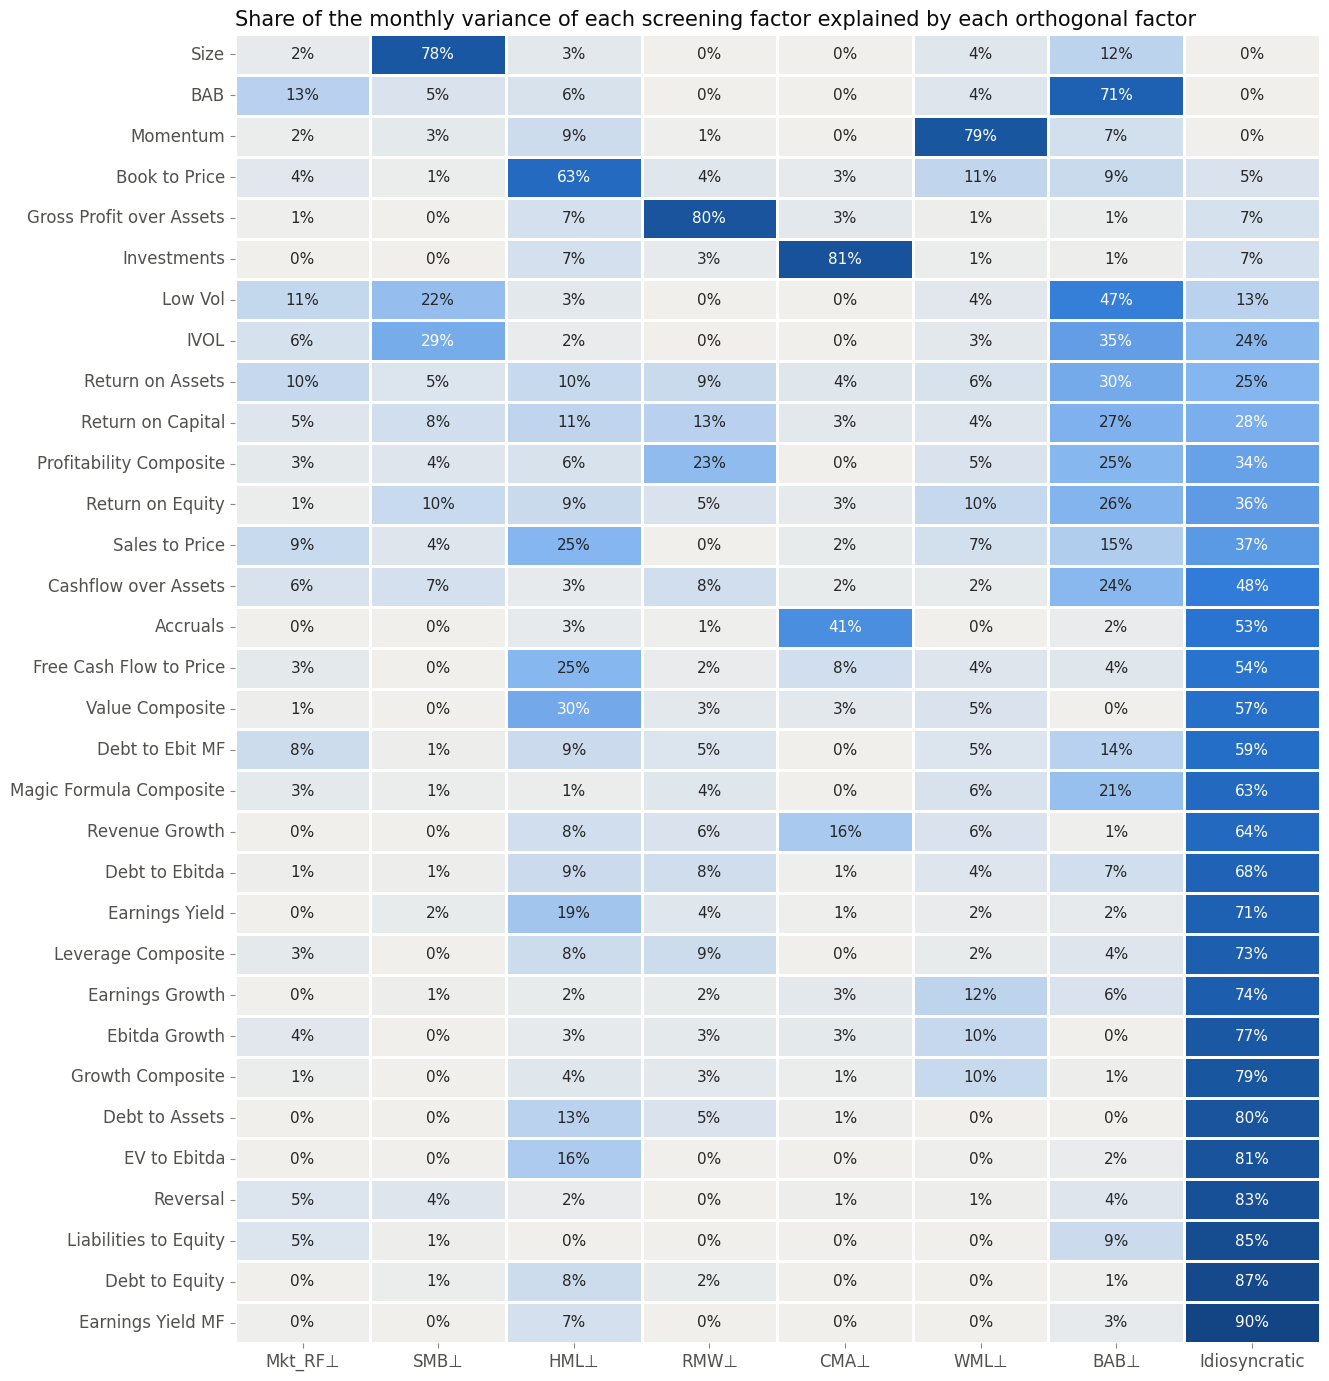

In [3]:
rows = {}
for name in screening.columns:
    result, dr2 = decompose(screening[name], factors, hac_lags = 4)
    rows[name] = pd.concat([dr2, pd.Series({'idiosyncratic': 1 - result.rsquared,
                                            'Alpha': result.params['const'] * 12, 't-statistic': result.tvalues['const'],
                                            'Volatility': screening[name].std() * np.sqrt(12), 'Months': result.nobs})])
table = pd.DataFrame(rows).T
table.insert(0, 'Group', table.index.map(group_of))
components = BRAZIL_FACTORS + ['idiosyncratic']
table = table.sort_values('idiosyncratic')

fig, ax = plt.subplots(figsize = (14, 17))
sns.heatmap(table[components].astype(float), annot = True, fmt = '.0%', cmap = SEQUENTIAL, vmin = 0, vmax = 1, cbar = False,
            linewidths = 2, linecolor = 'white', annot_kws = {'size': 11}, ax = ax)
ax.set_xticklabels([f'{f}⊥' for f in BRAZIL_FACTORS] + ['Idiosyncratic'])
ax.set_ylabel('')
ax.set_title('Share of the monthly variance of each screening factor explained by each orthogonal factor')
ax.grid(False)
plt.show()

The factors are sorted from the most to the least explained.

- **Copies of the local factors.** Size, Momentum and BAB are the same portfolios as SMB, WML and BAB, so the seven factors explain them fully. Even so, only 71% to 79% of their variance goes to their own orthogonal factor: it is the squared resemblance of [`02_brazil_factors`](02_brazil_factors.ipynb), 0.88² = 78% for SMB, because an original factor is a mix of the orthogonal ones. Book to Price, Gross Profit over Assets and Investments are close versions of HML, RMW and CMA built from trimmed z-scores, and the seven factors explain 93% to 95% of them.
- **Low risk and profitability lean on the low-beta bet.** BAB⊥ explains 47% of Low Vol, 35% of IVOL and 24% to 30% of the return on assets, equity and capital and of the cash flow over assets: in Brazil, the profitable companies have also been the low-beta ones.
- **Accruals load on investment.** CMA⊥ explains 41% of Accruals, in line with the studies that link accruals to the growth of the balance sheet.
- **Leverage, growth and several value ratios are largely new.** At least 80% of the variance of Debt to Assets, Debt to Equity, Liabilities to Equity, EV to Ebitda, Reversal and the Earnings Yield of the Magic Formula is idiosyncratic.

In [4]:
# The screening versions of six of the seven local factors: same signals, but z-scored and trimmed
pairs = {'Size': 'SMB', 'Book to Price': 'HML', 'Gross Profit over Assets': 'RMW', 'Investments': 'CMA', 'Momentum': 'WML', 'BAB': 'BAB'}
pd.DataFrame({name: {'Local factor': local, 'Correlation': screening[name].corr(factors[local]),
                     'Share of its own orthogonal factor': table.loc[name, local], 'R²': 1 - table.loc[name, 'idiosyncratic']}
              for name, local in pairs.items()}).T.style.format({'Correlation': '{:.2f}', 'Share of its own orthogonal factor': '{:.1%}',
                                                                 'R²': '{:.1%}'})

,Local factor,Correlation,Share of its own orthogonal factor,R²
Size,SMB,1.00,78.0%,100.0%
Book to Price,HML,0.97,62.5%,94.9%
Gross Profit over Assets,RMW,0.97,80.4%,93.4%
Investments,CMA,0.96,81.4%,93.0%
Momentum,WML,1.00,79.1%,100.0%
BAB,BAB,1.00,70.8%,100.0%


In [5]:
# Size, Momentum and BAB are the same daily series as SMB, WML and BAB, so they are left out of the averages,
# of the alphas and of the naive sums below
duplicates = [name for name, local in pairs.items() if (load_brazil_screening()[name] - load_brazil_factors()[local]).abs().max() == 0]
tested = table.drop(duplicates)
print('Identical to a local factor:', duplicates)

# Average shares by group of factors
tested.groupby('Group')[components].mean().loc[list(groups)].style.format('{:.1%}')

Identical to a local factor: ['Size', 'Momentum', 'BAB']


,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Group,,,,,,,,
Value,2.8%,1.4%,29.5%,2.2%,2.8%,5.0%,5.5%,50.8%
Profitability,3.6%,4.4%,6.3%,20.9%,8.9%,4.2%,18.0%,33.8%
Growth,1.0%,0.3%,4.7%,3.2%,21.1%,7.8%,1.6%,60.2%
Leverage,1.9%,0.6%,7.7%,4.8%,0.4%,1.4%,4.3%,78.9%
Market,7.4%,18.4%,2.3%,0.2%,0.3%,2.7%,28.8%,39.9%
Magic Formula,4.1%,2.5%,7.1%,5.6%,0.9%,3.9%,16.1%,60.0%


By group, the seven factors explain about two thirds of the profitability factors, which split mainly between RMW⊥ (21% on average) and BAB⊥ (18%), and about 60% of the low-risk and reversal factors. The value factors load on HML⊥ (30%) but keep half of their variance unexplained, and the growth factors load on CMA⊥ (21%) and keep 60%. The leverage factors are the least explained group, with 79% of their variance idiosyncratic: the local model has no factor for financial leverage.

## Alphas

The intercept of each regression is the return of the screening factor that the seven local factors do not explain, the same with the original and the orthogonal factors. Newey-West t-statistics with 4 lags.

In [6]:
alphas = tested[['Group', 'Alpha', 't-statistic', 'Volatility', 'Months']].sort_values('t-statistic', ascending = False)
alphas.style.format({'Alpha': '{:.2%}', 't-statistic': '{:.2f}', 'Volatility': '{:.2%}', 'Months': '{:.0f}'})

,Group,Alpha,t-statistic,Volatility,Months
Debt to Assets,Leverage,7.31%,3.21,9.86%,197
Return on Capital,Magic Formula,6.48%,2.70,18.43%,197
Debt to Equity,Leverage,6.70%,2.67,10.05%,197
Accruals,Profitability,5.05%,2.25,11.09%,197
IVOL,Market,5.98%,2.21,18.67%,196
Debt to Ebit MF,Magic Formula,6.18%,2.16,13.76%,197
Book to Price,Value,2.17%,2.14,15.69%,197
Low Vol,Market,5.02%,2.06,22.14%,197
Value Composite,Value,4.05%,1.68,12.04%,195
Liabilities to Equity,Leverage,3.94%,1.68,9.09%,197


Eight of the 29 factors have a t-statistic above 2. The strongest are low leverage (Debt to Assets, 7.3% a year with a t-statistic of 3.2, and Debt to Equity, 6.7%) and the return on capital of the Magic Formula (6.5%), followed by Accruals, low idiosyncratic volatility, low net debt to EBIT, book to price and low volatility. The leverage factors are also the ones the seven factors explain least, which makes low leverage the clearest candidate for a factor missing from the local model.

With 29 tests, one or two t-statistics beyond 2 are expected by chance alone, and only Debt to Assets passes a Bonferroni correction at 5%, which needs a t-statistic of about 3.1. These are in-sample results before costs.

## The naive sum

As in Table 5 of the paper, the sum of $(\beta_k \sigma_k)^2$ with the original factors against the systematic variance.

In [7]:
ratio = pd.Series({name: (lambda t: t.loc['sum', 'original'] / t.loc['systematic', 'original'])(variance_levels(screening[name], factors))
                   for name in tested.index}).loc[tested.index]
ratio.describe()[['min', '25%', '50%', '75%', 'max']].rename('Naive sum / systematic variance').to_frame().T.round(2)

,min,25%,50%,75%,max
Naive sum / systematic variance,0.44,0.67,0.89,1.11,4.98


The naive sum misses the systematic variance in both directions. The median ratio is 0.89, but it goes from 0.44 to 4.98, so ignoring the correlations between the factors can understate the factor risk of a portfolio by half or overstate it fivefold.

In [8]:
table.join(ratio.rename('Naive sum / systematic variance')).round(4).to_csv('results/screening_decomposition.csv')